# B14 – Phát Hiện Mã Độc Bằng Support Vector Machine (SVM)
## Đặc Trưng Tĩnh PE Header – Dataset Malware-Benign

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, brier_score_loss,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
ROOT_DIR = Path.cwd()
_name = "Malware-Benign.csv"
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR.parent / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR / "Dataset" / "malware-benignpe-files" / _name,
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

# ==========================
# NHÃN (LABELS)
# ==========================
LABEL_COL = "Malware"               # 0 = file lành tính, 1 = mã độc
TARGET_NAMES = ["Benign", "Malware"]
ID_COL = "Hash_md5_Name"            # cột định danh, bỏ TRƯỚC khi lọc trùng
META_COLS = []

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 70% train / 30% test
CV_FOLDS = 5       # số fold của cross-validation

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ SVM
# ==========================
# C      : tham số điều chuẩn. C nhỏ → biên rộng, chấp nhận nhiều lỗi
#          huấn luyện (dễ underfit). C lớn → biên hẹp, bám sát dữ liệu
#          (dễ overfit).
# gamma  : bán kính ảnh hưởng của mỗi support vector trong kernel RBF.
#          'scale' là mặc định của sklearn, bằng 1/(n_features × var(X)).
# Hai tham số này TƯƠNG TÁC với nhau nên phải dò theo lưới hai chiều.
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
GAMMA_GRID = ["scale", 0.001, 0.01, 0.1, 1.0]

# GRID_N: cỡ tập con dùng để dò siêu tham số ở các phần A2–A4. SVM đắt theo
# bình phương số mẫu nên dò lưới trên toàn bộ tập train là không khả thi;
# mô hình cuối ở A8 mới huấn luyện lại trên toàn bộ tập train.
GRID_N = 5000

# MAX_ITER: chặn trên số vòng lặp của libsvm. Mặc định của sklearn là -1,
# tức KHÔNG giới hạn — trên dữ liệu không phân tách tuyến tính được,
# SVC(kernel='linear') có thể chạy hàng chục phút mà vẫn chưa hội tụ.
MAX_ITER = 200000

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
KERNEL_COMMENT = (
    "\nNhận xét: RBF thắng (0,9748), nhưng khoảng cách với kernel tuyến tính\n"
    "(0,9716) rất nhỏ. Kernel đa thức bậc 3 tụt mạnh xuống 0,9101 — bậc cao làm\n"
    "biên quyết định uốn quá mức trên dữ liệu PE header nhiều ngoại lai.\n"
    "LinearSVC là mô hình CHẬM NHẤT (3,61s, gấp hơn 10 lần SVC-RBF) dù về lý\n"
    "thuyết nó được tối ưu cho trường hợp tuyến tính. Nguyên nhân: dữ liệu PE\n"
    "không phân tách tuyến tính được nên liblinear chạy hết số vòng lặp cho phép\n"
    "mà vẫn chưa hội tụ.")
C_COMMENT = (
    "\nNhận xét: F1 tăng đều từ 0,891 (C=0,01) lên 0,981 (C=100). Ở C=0,01 có tới\n"
    "58% tập train là support vector — mô hình gần như ghi nhớ mọi mẫu vì biên quá\n"
    "rộng; ở C=100 chỉ còn 8,7%. Khác với dữ liệu lưu lượng mạng, ở đây cần C lớn\n"
    "hơn mới đạt hiệu năng tốt, cho thấy hai lớp chồng lấn nhiều hơn.")
GRID_COMMENT = (
    "\nNhận xét: cấu hình tốt nhất (C=100, gamma='scale') đạt 0,9812, cải thiện\n"
    "thực sự so với 0,9748 của RBF mặc định ở A2 — khác với bộ dữ liệu của CV4.1,\n"
    "ở đây việc dò lưới có giá trị. Ô kém nhất trong lưới chỉ đạt 0,8246.\n"
    "Đọc heatmap theo hàng sẽ thấy quy luật: với gamma lớn (0,1 và 1,0) thì tăng C\n"
    "gần như không giúp gì, vì biên đã quá gấp khúc; vùng tham số tốt nằm ở gamma\n"
    "nhỏ kết hợp C lớn.")
COST_COMMENT = (
    "\nNhận xét: thời gian huấn luyện tăng gần theo bình phương số mẫu. Tỷ lệ\n"
    "support vector giảm từ 16,4% xuống 7,5% khi tập train lớn hơn — mô hình không\n"
    "phình ra tỷ lệ thuận với dữ liệu.\n"
    "Với một hãng antivirus có cơ sở dữ liệu hàng chục triệu mẫu, con số này vẫn\n"
    "khiến SVM bất khả thi: huấn luyện lại định kỳ sẽ mất hàng ngày.")
CW_COMMENT = (
    "\nNhận xét: class_weight='balanced' nâng Precision một chút, hạ Recall một\n"
    "chút, F1 gần như không đổi. Giống bộ dữ liệu của CV4.1, lớp dương (mã độc,\n"
    "70%) lại là lớp đa số nên tham số này không có tác dụng như kỳ vọng.")
PROB_COMMENT = (
    "\nNhận xét: Brier score ≈0,02 — cao hơn bộ dữ liệu của CV4.1 khoảng ba lần,\n"
    "phản ánh hai lớp chồng lấn nhiều hơn. Hiệu chỉnh isotonic cho Brier tốt hơn\n"
    "Platt một chút và tốn ít thời gian hơn.\n"
    "Với sản phẩm diệt virus, xác suất đáng tin cho phép đặt ngưỡng chặn sao cho\n"
    "tỷ lệ báo động giả nằm dưới một mức cho trước — nên ở đây cái giá 4 lần thời\n"
    "gian huấn luyện là đáng trả.")
FINAL_COMMENT = (
    "\nNhận xét: hạ ngưỡng từ 0 xuống -0,228 nâng F1 từ 0,9822 lên 0,9828 — cải\n"
    "thiện nhỏ nhưng theo đúng hướng, và lần này ngưỡng tối ưu khác 0 thật.\n"
    "Random Forest vẫn vượt rõ (F1 0,9937, AUC 0,9983 so với 0,9828 và 0,9871).\n"
    "Quan trọng hơn: trên bộ dữ liệu này Random Forest còn huấn luyện NHANH HƠN\n"
    "SVM (khoảng 1s so với 2s), nên SVM không có lợi thế nào còn lại. Mô hình cuối\n"
    "báo giả 98 file lành tính — với antivirus đây là loại lỗi đắt nhất.")
KFOLD_COMMENT = (
    "\nNhận xét: độ lệch chuẩn nhỏ (0,0014) → kết quả ổn định. Con số này chỉ đáng\n"
    "tin vì đã lọc trùng ở A1; nếu còn dòng trùng lặp thì cross-validation cũng bị\n"
    "thổi phồng y như một lần chia đơn lẻ.")

print("✅ Cấu hình xong!")
print(f"   Nhãn       → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   Test size  → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}  |  CV folds = {CV_FOLDS}")
print(f"   C_GRID     → {C_GRID}")
print(f"   GAMMA_GRID → {GAMMA_GRID}")
print(f"   Tổng số cấu hình cần dò ở phần A4: {len(C_GRID) * len(GAMMA_GRID)}")
print(f"   GRID_N     → {GRID_N} (cỡ tập con dùng để dò siêu tham số)")
print(f"   MAX_ITER   → {MAX_ITER}")


✅ Cấu hình xong!
   Nhãn       → Malware (0 = Benign, 1 = Malware)
   Test size  → 30%  |  SEED = 42  |  CV folds = 5
   C_GRID     → [0.01, 0.1, 1.0, 10.0, 100.0]
   GAMMA_GRID → ['scale', 0.001, 0.01, 0.1, 1.0]
   Tổng số cấu hình cần dò ở phần A4: 25
   GRID_N     → 5000 (cỡ tập con dùng để dò siêu tham số)
   MAX_ITER   → 200000


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0.

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó — dùng cho tập
    held-out, tập này buộc phải có đúng bộ đặc trưng của tập train.
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
# Khác với KNN và Naive Bayes, SVM KHÔNG cho ra xác suất. Nó trả về
# decision_function — khoảng cách có dấu từ mẫu tới siêu phẳng phân tách.
# Giá trị dương nghĩa là thuộc lớp 1, âm là lớp 0, và |giá trị| càng lớn
# nghĩa là mẫu càng nằm xa biên. Đại lượng này đủ để xếp hạng nên tính được
# AUC-ROC, nhưng không phải xác suất nên không tính được Brier score.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


print("✅ Đã định nghĩa clean_numeric() và evaluate()")


✅ Đã định nghĩa clean_numeric() và evaluate()


---
# Xây Dựng Mô Hình SVM

> **Bài toán:** Dự đoán một file thực thi là **Benign (0)** hay **Malware (1)** chỉ từ đặc trưng tĩnh của PE header.
>
> **Ý tưởng của SVM:** tìm siêu phẳng có biên lớn nhất giữa hai lớp; khi dữ liệu không phân tách tuyến tính được, dùng kernel trick để làm việc trong không gian nhiều chiều hơn mà không phải ánh xạ tường minh.
>
> **Điều bài này tập trung vào:** so sánh các kernel, dò lưới C × gamma, và xử lý vấn đề SVM không cho ra xác suất.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU PE HEADER (Malware-Benign)")
print("═" * 70)
print("Đường dẫn:", CSV_PATH)

df = pd.read_csv(CSV_PATH)
print(f"\nShape gốc : {df.shape}")

# Bỏ cột định danh TRƯỚC khi lọc trùng — nếu giữ lại thì mỗi dòng đều có giá
# trị hash riêng, không dòng nào bị coi là trùng và drop_duplicates() vô hiệu.
n_before = len(df)
df = df.drop(columns=[ID_COL]).drop_duplicates().reset_index(drop=True)
print(f"Sau khi bỏ {ID_COL} và lọc trùng: {df.shape} "
      f"(loại {n_before - len(df):,} dòng trùng)")

y = df[LABEL_COL].astype(int).values
print(f"Phân phối nhãn: {TARGET_NAMES[0]}(0) = {int((y == 0).sum()):,} | "
      f"{TARGET_NAMES[1]}(1) = {int((y == 1).sum()):,} "
      f"({(y == 1).mean()*100:.2f}% mã độc)")

X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý: loại {len(zero_var)} cột phương sai = 0 → "
      f"{X_raw.shape[1]} đặc trưng, {X_raw.shape[0]:,} mẫu")

# ── Chia train/test TRƯỚC, chuẩn hóa SAU ────────────────────────────────────
# SVM dựa trên khoảng cách nên RẤT nhạy với thang đo đặc trưng — chuẩn hóa ở
# đây là bắt buộc, không phải tùy chọn như với Naive Bayes. Scaler chỉ được
# fit trên tập train; nếu fit trên toàn bộ dữ liệu thì thông tin của tập test
# đã lọt vào mô hình.
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_tr_raw)
X_tr = scaler.transform(X_tr_raw)
X_te = scaler.transform(X_te_raw)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} dương)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} dương)")
print(f"   Tỷ lệ lớp dương trong train: {y_tr.mean()*100:.2f}%")

# Tập con để dò siêu tham số ở các phần A2, A3, A4. Tập train đã được
# train_test_split trộn ngẫu nhiên nên lấy phần đầu là đủ.
n_g = min(GRID_N, X_tr.shape[0])
X_g, y_g = X_tr[:n_g], y_tr[:n_g]
print(f"   Tập con dò siêu tham số: {n_g:,} mẫu ({y_g.mean()*100:.2f}% dương)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU PE HEADER (Malware-Benign)
══════════════════════════════════════════════════════════════════════
Đường dẫn: C:\Desktop\VANN\BÀI THỰC HÀNH C07\CV4.2\CV4.2\Dataset\Dataset\malware-benignpe-files\Malware-Benign.csv

Shape gốc : (19611, 79)


Sau khi bỏ Hash_md5_Name và lọc trùng: (16640, 78) (loại 2,971 dòng trùng)
Phân phối nhãn: Benign(0) = 4,966 | Malware(1) = 11,674 (70.16% mã độc)



✅ Sau tiền xử lý: loại 8 cột phương sai = 0 → 69 đặc trưng, 16,640 mẫu

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 11,648 mẫu (8,172 dương)
   Test  : 4,992 mẫu (3,502 dương)
   Tỷ lệ lớp dương trong train: 70.16%
   Tập con dò siêu tham số: 5,000 mẫu (71.18% dương)


### A2. So Sánh Các Kernel

                                 acc    prec     rec      f1     auc   fit_s  \
model                                                                          
LinearSVC (liblinear)         0.9577  0.9697  0.9700  0.9699  0.9727  2.1538   
SVC kernel='linear'           0.9599  0.9666  0.9766  0.9716  0.9737  0.4391   
SVC kernel='rbf'              0.9643  0.9663  0.9834  0.9748  0.9805  0.3486   
SVC kernel='poly' (degree=3)  0.8630  0.8428  0.9891  0.9101  0.9686  0.5911   
SVC kernel='sigmoid'          0.9305  0.9584  0.9417  0.9500  0.9561  0.3297   

                                n_sv  
model                                 
LinearSVC (liblinear)            NaN  
SVC kernel='linear'            648.0  
SVC kernel='rbf'               855.0  
SVC kernel='poly' (degree=3)  2004.0  
SVC kernel='sigmoid'           887.0  

Nhận xét: RBF thắng (0,9748), nhưng khoảng cách với kernel tuyến tính
(0,9716) rất nhỏ. Kernel đa thức bậc 3 tụt mạnh xuống 0,9101 — bậc cao làm
biên quyết định uốn 

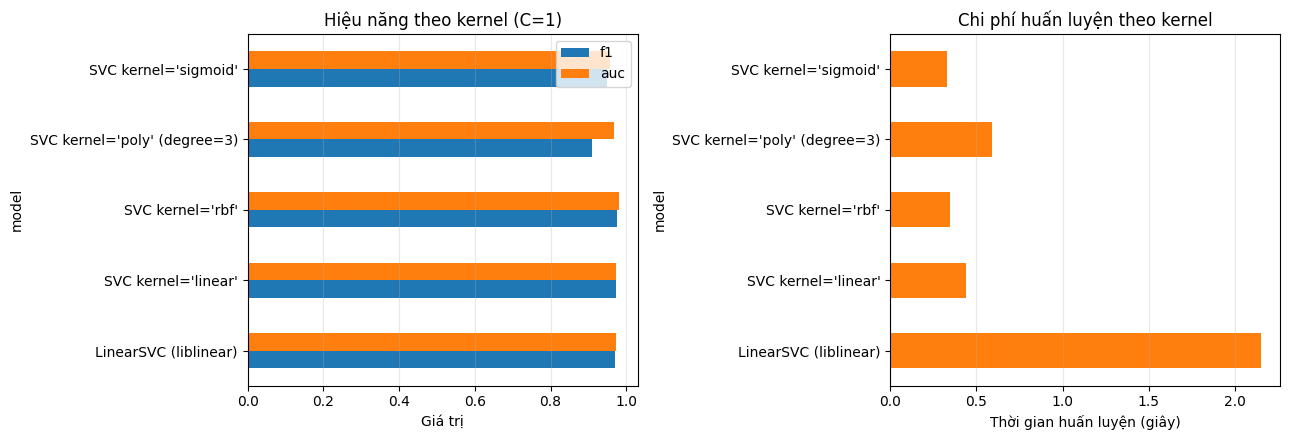

In [5]:
# SVM tìm siêu phẳng phân tách hai lớp sao cho BIÊN (margin) — khoảng cách từ
# siêu phẳng tới các mẫu gần nhất — là lớn nhất. Những mẫu nằm đúng trên biên
# gọi là support vector; chỉ chúng quyết định siêu phẳng, các mẫu còn lại
# không ảnh hưởng gì.
#
# Khi hai lớp không phân tách được bằng một mặt phẳng, SVM dùng KERNEL TRICK:
# thay vì ánh xạ dữ liệu sang không gian nhiều chiều hơn rồi tính ở đó, nó
# chỉ cần tính tích vô hướng trong không gian mới bằng một hàm kernel trên dữ
# liệu gốc. Nhờ đó tránh được chi phí của phép ánh xạ tường minh.
#
#   linear      K(x, z) = xᵀz                     → biên là siêu phẳng
#   rbf         K(x, z) = exp(-gamma‖x - z‖²)     → biên cong, cục bộ
#   poly        K(x, z) = (gamma·xᵀz + r)^degree  → biên đa thức
#   sigmoid     K(x, z) = tanh(gamma·xᵀz + r)     → không phải kernel hợp lệ
#                                                   với mọi tham số
#
# LinearSVC khác SVC(kernel='linear') ở chỗ dùng thuật toán liblinear tối ưu
# riêng cho trường hợp tuyến tính, và tối thiểu hóa squared hinge loss.
rows = []
specs = [
    ("LinearSVC (liblinear)", LinearSVC(C=1.0, max_iter=5000, random_state=SEED)),
    ("SVC kernel='linear'", SVC(max_iter=MAX_ITER, kernel="linear", C=1.0)),
    ("SVC kernel='rbf'", SVC(max_iter=MAX_ITER, kernel="rbf", C=1.0, gamma="scale")),
    ("SVC kernel='poly' (degree=3)", SVC(max_iter=MAX_ITER, kernel="poly", degree=3, C=1.0, gamma="scale")),
    ("SVC kernel='sigmoid'", SVC(max_iter=MAX_ITER, kernel="sigmoid", C=1.0, gamma="scale")),
]
for tag, m in specs:
    t0 = time.perf_counter()
    m.fit(X_g, y_g)                 # dò trên tập con — xem phần A5 để biết lý do
    tf = time.perf_counter() - t0
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), tag)
    r["fit_s"] = tf
    r["n_sv"] = int(m.n_support_.sum()) if hasattr(m, "n_support_") else np.nan
    rows.append(r)

ker_df = pd.DataFrame(rows).set_index("model").round(4)
print(ker_df[["acc", "prec", "rec", "f1", "auc", "fit_s", "n_sv"]])
print(KERNEL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ker_df[["f1", "auc"]].plot.barh(ax=axes[0])
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Hiệu năng theo kernel (C=1)")
axes[0].grid(axis="x", alpha=.3)

ker_df["fit_s"].plot.barh(ax=axes[1], color="tab:orange")
axes[1].set_xlabel("Thời gian huấn luyện (giây)")
axes[1].set_title("Chi phí huấn luyện theo kernel")
axes[1].grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Tham Số C – Đánh Đổi Giữa Biên Rộng Và Lỗi Huấn Luyện

           acc    prec     rec      f1     auc  n_sv  sv_ratio
C                                                             
0.01    0.8285  0.8062  0.9946  0.8906  0.9646  2888    0.5776
0.10    0.9529  0.9574  0.9763  0.9668  0.9735  1528    0.3056
1.00    0.9643  0.9663  0.9834  0.9748  0.9805   855    0.1710
10.00   0.9718  0.9703  0.9900  0.9801  0.9846   614    0.1228
100.00  0.9734  0.9738  0.9886  0.9812  0.9858   437    0.0874

Nhận xét: F1 tăng đều từ 0,891 (C=0,01) lên 0,981 (C=100). Ở C=0,01 có tới
58% tập train là support vector — mô hình gần như ghi nhớ mọi mẫu vì biên quá
rộng; ở C=100 chỉ còn 8,7%. Khác với dữ liệu lưu lượng mạng, ở đây cần C lớn
hơn mới đạt hiệu năng tốt, cho thấy hai lớp chồng lấn nhiều hơn.


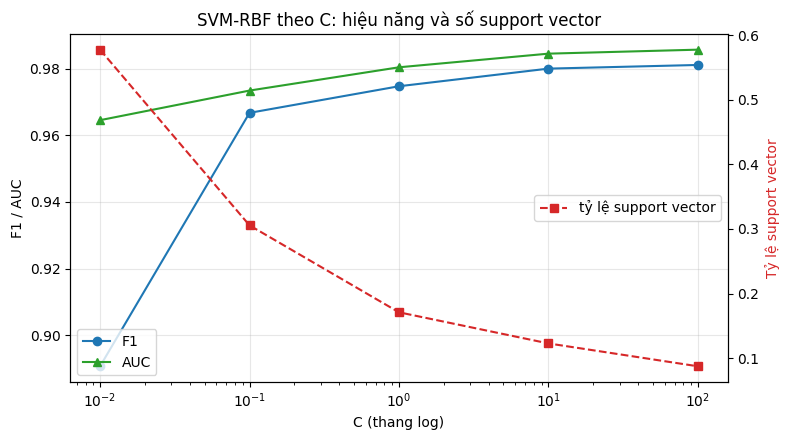

In [6]:
# C là tham số điều chuẩn (regularization), điều khiển đánh đổi giữa:
#   - BIÊN RỘNG (C nhỏ): mô hình chấp nhận nhiều mẫu bị phân loại sai hoặc
#     nằm trong biên, đổi lại biên rộng và mô hình đơn giản → dễ underfit
#   - ÍT LỖI HUẤN LUYỆN (C lớn): mô hình cố phân loại đúng mọi mẫu train,
#     biên hẹp lại và bám sát dữ liệu → dễ overfit
#
# Một dấu hiệu quan sát được: C nhỏ cho NHIỀU support vector hơn, vì biên
# rộng nên nhiều mẫu rơi vào trong biên.
rows = []
for C in C_GRID:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C, gamma="scale").fit(X_g, y_g)
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), C)
    r["n_sv"] = int(m.n_support_.sum())
    r["sv_ratio"] = m.n_support_.sum() / len(y_g)
    rows.append(r)

c_df = pd.DataFrame(rows).set_index("model").round(4)
c_df.index.name = "C"
print(c_df[["acc", "prec", "rec", "f1", "auc", "n_sv", "sv_ratio"]])
print(C_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.semilogx(c_df.index, c_df["f1"], marker="o", color="tab:blue", label="F1")
ax1.semilogx(c_df.index, c_df["auc"], marker="^", color="tab:green", label="AUC")
ax1.set_xlabel("C (thang log)")
ax1.set_ylabel("F1 / AUC")
ax1.grid(alpha=.3)
ax1.legend(loc="lower left")
ax2 = ax1.twinx()
ax2.semilogx(c_df.index, c_df["sv_ratio"], marker="s", ls="--",
             color="tab:red", label="tỷ lệ support vector")
ax2.set_ylabel("Tỷ lệ support vector", color="tab:red")
ax2.legend(loc="center right")
ax1.set_title("SVM-RBF theo C: hiệu năng và số support vector")
plt.tight_layout()
plt.show()


### A4. Dò Lưới Hai Chiều C × gamma

Dò 5×5 = 25 cấu hình trên tập con 5,000 mẫu — mất 55.0 giây

    C gamma     f1    auc  n_sv
100.0 scale 0.9812 0.9858   437
100.0  0.01 0.9809 0.9856   440
 10.0   0.1 0.9806 0.9877   815
 10.0 scale 0.9801 0.9846   614
 10.0  0.01 0.9796 0.9835   626

→ Cấu hình tốt nhất: C = 100, gamma = scale  (F1 = 0.9812)

Nhận xét: cấu hình tốt nhất (C=100, gamma='scale') đạt 0,9812, cải thiện
thực sự so với 0,9748 của RBF mặc định ở A2 — khác với bộ dữ liệu của CV4.1,
ở đây việc dò lưới có giá trị. Ô kém nhất trong lưới chỉ đạt 0,8246.
Đọc heatmap theo hàng sẽ thấy quy luật: với gamma lớn (0,1 và 1,0) thì tăng C
gần như không giúp gì, vì biên đã quá gấp khúc; vùng tham số tốt nằm ở gamma
nhỏ kết hợp C lớn.


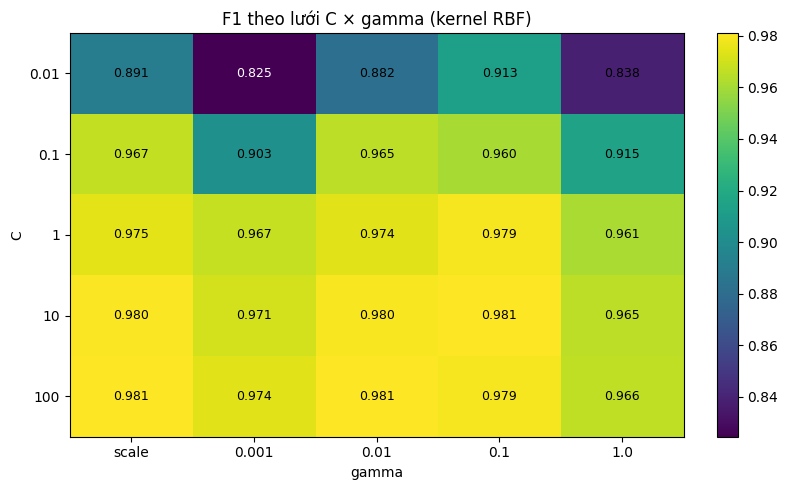

In [7]:
# gamma của kernel RBF điều khiển "bán kính ảnh hưởng" của mỗi support
# vector: K(x, z) = exp(-gamma‖x - z‖²).
#   gamma nhỏ → ảnh hưởng lan rộng, biên quyết định mượt, gần như tuyến tính
#   gamma lớn → ảnh hưởng chỉ quanh từng mẫu, biên cực kỳ gấp khúc, overfit
#
# Mặc định gamma='scale' của sklearn bằng 1 / (số đặc trưng × phương sai của
# dữ liệu). Vì dữ liệu đã chuẩn hóa nên phương sai xấp xỉ 1, tức
# gamma ≈ 1 / số đặc trưng.
#
# C và gamma tương tác với nhau nên phải dò theo LƯỚI HAI CHIỀU, không thể dò
# lần lượt từng tham số.
#
# Việc dò được thực hiện trên TẬP CON X_g (xem phần A5 để biết vì sao): SVM
# đắt theo bình phương số mẫu nên dò lưới trên toàn bộ tập train là không
# khả thi. Mô hình cuối ở phần A8 mới huấn luyện lại trên toàn bộ tập train.
rows = []
t0 = time.perf_counter()
for C in C_GRID:
    for g in GAMMA_GRID:
        m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C, gamma=g).fit(X_g, y_g)
        r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te),
                     f"{C}|{g}")
        r["C"], r["gamma"] = C, str(g)
        r["n_sv"] = int(m.n_support_.sum())
        rows.append(r)
grid_time = time.perf_counter() - t0

grid_df = pd.DataFrame(rows)
print(f"Dò {len(C_GRID)}×{len(GAMMA_GRID)} = {len(rows)} cấu hình trên tập con "
      f"{len(y_g):,} mẫu — mất {grid_time:.1f} giây")
print()
print(grid_df.sort_values("f1", ascending=False)
      .head(5)[["C", "gamma", "f1", "auc", "n_sv"]].round(4).to_string(index=False))

best = grid_df.loc[grid_df["f1"].idxmax()]
C_BEST = float(best["C"])
GAMMA_BEST = best["gamma"] if best["gamma"] == "scale" else float(best["gamma"])
print(f"\n→ Cấu hình tốt nhất: C = {C_BEST:g}, gamma = {best['gamma']}"
      f"  (F1 = {best['f1']:.4f})")
print(GRID_COMMENT)

pivot = grid_df.pivot(index="C", columns="gamma", values="f1")
pivot = pivot[[str(g) for g in GAMMA_GRID]]
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), [f"{c:g}" for c in pivot.index])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("F1 theo lưới C × gamma (kernel RBF)")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color="white" if v < pivot.values.max() * 0.85 else "black",
                fontsize=9)
plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.show()


### A5. Support Vector & Chi Phí Tính Toán

          fit_s  pred_ms_per_sample  n_sv  sv_ratio
n_train                                            
1000     0.0164              0.0164   164    0.1640
2500     0.0781              0.0306   308    0.1232
5000     0.2629              0.0435   437    0.0874
10000    1.3234              0.0788   769    0.0769
11648    1.6438              0.0979   869    0.0746

Độ dốc trên thang log-log: thời gian huấn luyện ≈ n^1.90

Nhận xét: thời gian huấn luyện tăng gần theo bình phương số mẫu. Tỷ lệ
support vector giảm từ 16,4% xuống 7,5% khi tập train lớn hơn — mô hình không
phình ra tỷ lệ thuận với dữ liệu.
Với một hãng antivirus có cơ sở dữ liệu hàng chục triệu mẫu, con số này vẫn
khiến SVM bất khả thi: huấn luyện lại định kỳ sẽ mất hàng ngày.


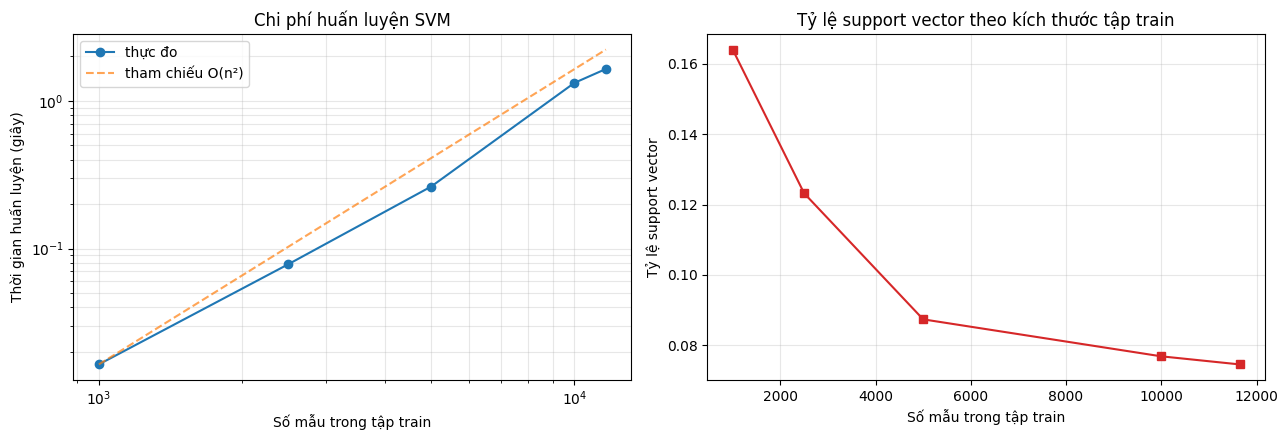

In [8]:
# Huấn luyện SVM đòi hỏi giải một bài toán tối ưu bậc hai có kích thước bằng
# số mẫu. Chi phí thực tế của libsvm nằm giữa O(n²) và O(n³) theo số mẫu —
# đây là lý do SVM không dùng được trực tiếp cho tập dữ liệu hàng triệu mẫu.
#
# Khi dự đoán, chi phí tỷ lệ với SỐ SUPPORT VECTOR chứ không phải số mẫu
# train. Mô hình có ít support vector sẽ vừa nhẹ vừa nhanh.
N_PROBE = 2000
rows = []
for n in [1000, 2500, 5000, 10000, X_tr.shape[0]]:
    if n > X_tr.shape[0]:
        continue
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST)
    t0 = time.perf_counter()
    m.fit(X_tr[:n], y_tr[:n])
    tf = time.perf_counter() - t0
    t0 = time.perf_counter()
    m.predict(X_te[:N_PROBE])
    tp = time.perf_counter() - t0
    rows.append({"n_train": n, "fit_s": tf,
                 "pred_ms_per_sample": tp / N_PROBE * 1000,
                 "n_sv": int(m.n_support_.sum()),
                 "sv_ratio": m.n_support_.sum() / n})

cost_df = pd.DataFrame(rows).set_index("n_train").round(4)
print(cost_df)

# Ước lượng số mũ của chi phí: nếu fit_s ∝ n^k thì log(fit_s) là hàm bậc một
# của log(n), và k chính là độ dốc.
k = np.polyfit(np.log(cost_df.index.values.astype(float)),
               np.log(cost_df["fit_s"].values), 1)[0]
print(f"\nĐộ dốc trên thang log-log: thời gian huấn luyện ≈ n^{k:.2f}")
print(COST_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(cost_df.index, cost_df["fit_s"], marker="o", label="thực đo")
ref = cost_df["fit_s"].iloc[0] * (cost_df.index / cost_df.index[0]) ** 2
axes[0].loglog(cost_df.index, ref, ls="--", alpha=.7, label="tham chiếu O(n²)")
axes[0].set_xlabel("Số mẫu trong tập train")
axes[0].set_ylabel("Thời gian huấn luyện (giây)")
axes[0].set_title("Chi phí huấn luyện SVM")
axes[0].legend()
axes[0].grid(alpha=.3, which="both")

axes[1].plot(cost_df.index, cost_df["sv_ratio"], marker="s", color="tab:red")
axes[1].set_xlabel("Số mẫu trong tập train")
axes[1].set_ylabel("Tỷ lệ support vector")
axes[1].set_title("Tỷ lệ support vector theo kích thước tập train")
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A6. Mất Cân Bằng Lớp Với class_weight

Tỷ lệ lớp dương trong tập train: 70.16%

                            acc    prec     rec      f1  f1_macro     auc  \
model                                                                       
class_weight=None        0.9748  0.9739  0.9906  0.9822    0.9695  0.9871   
class_weight='balanced'  0.9744  0.9774  0.9863  0.9818    0.9692  0.9884   

                         n_sv  
model                          
class_weight=None         869  
class_weight='balanced'  1034  

Chênh lệch khi bật balanced: Recall -0.0043 | Precision +0.0035 | F1 -0.0004

Nhận xét: class_weight='balanced' nâng Precision một chút, hạ Recall một
chút, F1 gần như không đổi. Giống bộ dữ liệu của CV4.1, lớp dương (mã độc,
70%) lại là lớp đa số nên tham số này không có tác dụng như kỳ vọng.


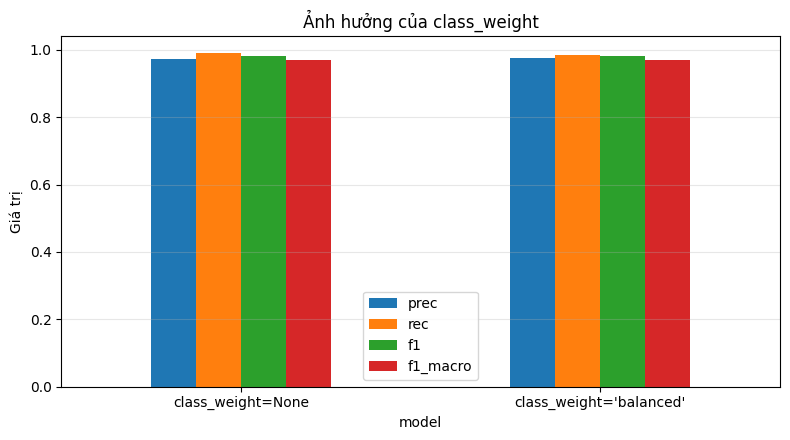

In [9]:
# Dữ liệu mất cân bằng khiến SVM có xu hướng ưu tiên lớp đa số: đẩy siêu
# phẳng về phía lớp thiểu số để giảm tổng lỗi. Tham số class_weight='balanced'
# nhân trọng số của mỗi lớp tỷ lệ nghịch với tần suất, tương đương việc phạt
# nặng hơn khi phân loại sai mẫu thuộc lớp thiểu số.
#
# Lưu ý: đây KHÔNG phải lựa chọn luôn đúng. Nó nâng Recall nhưng thường hạ
# Precision, nên tác động lên F1 có thể theo chiều nào cũng được.
rows = []
for tag, w in [("class_weight=None", None), ("class_weight='balanced'", "balanced")]:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=w).fit(X_tr, y_tr)
    r = evaluate(y_te, m.predict(X_te), m.decision_function(X_te), tag)
    r["n_sv"] = int(m.n_support_.sum())
    rows.append(r)

cw_df = pd.DataFrame(rows).set_index("model").round(4)
print(f"Tỷ lệ lớp dương trong tập train: {y_tr.mean()*100:.2f}%")
print()
print(cw_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "n_sv"]])
print(f"\nChênh lệch khi bật balanced: Recall {rows[1]['rec'] - rows[0]['rec']:+.4f} | "
      f"Precision {rows[1]['prec'] - rows[0]['prec']:+.4f} | "
      f"F1 {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(CW_COMMENT)

ax = cw_df[["prec", "rec", "f1", "f1_macro"]].plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylabel("Giá trị")
ax.set_title("Ảnh hưởng của class_weight")
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A7. Xác Suất Từ SVM – Platt Scaling

                                      acc    prec     rec      f1     auc  \
model                                                                       
SVC(probability=True) — Platt      0.9748  0.9739  0.9906  0.9822  0.9871   
CalibratedClassifierCV — isotonic  0.9756  0.9750  0.9906  0.9827  0.9888   

                                    brier   fit_s  
model                                              
SVC(probability=True) — Platt      0.0205  9.2537  
CalibratedClassifierCV — isotonic  0.0191  6.5920  

Thời gian huấn luyện SVM thuần: 1.72s
   probability=True        : 9.25s  → chậm hơn 5.4 lần
   CalibratedClassifierCV  : 6.59s  → chậm hơn 3.8 lần

Nhận xét: Brier score ≈0,02 — cao hơn bộ dữ liệu của CV4.1 khoảng ba lần,
phản ánh hai lớp chồng lấn nhiều hơn. Hiệu chỉnh isotonic cho Brier tốt hơn
Platt một chút và tốn ít thời gian hơn.
Với sản phẩm diệt virus, xác suất đáng tin cho phép đặt ngưỡng chặn sao cho
tỷ lệ báo động giả nằm dưới một mức cho trước — nên ở đây cái giá 4

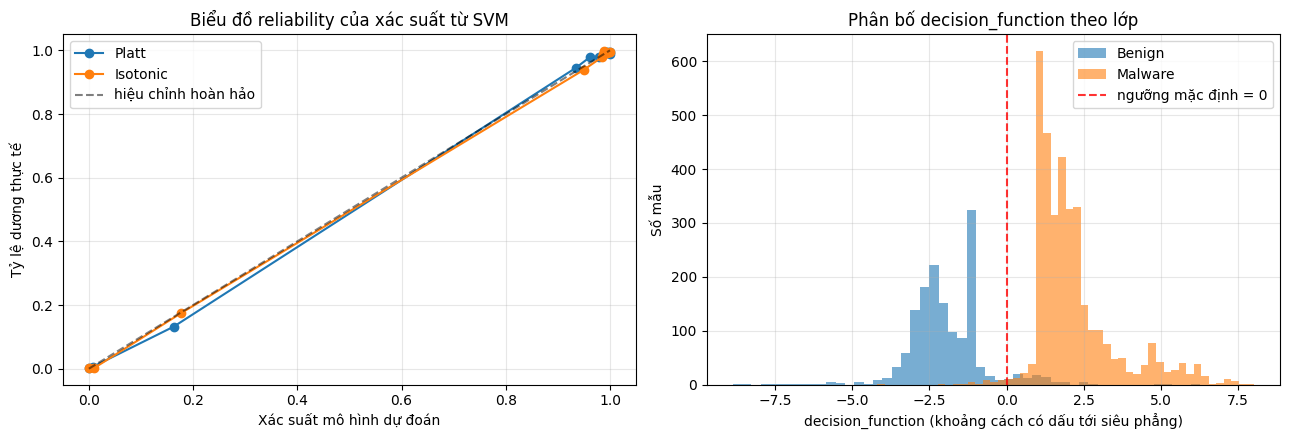

In [10]:
# SVM không phải mô hình xác suất. Để có xác suất, sklearn dùng Platt
# scaling: huấn luyện thêm một hồi quy logistic trên giá trị
# decision_function, với cross-validation nội bộ 5 fold. Hệ quả là
# probability=True làm thời gian huấn luyện tăng nhiều lần.
#
# Ta đo cả chất lượng xác suất (Brier score) lẫn chi phí của hai cách lấy
# xác suất, và so với việc chỉ dùng decision_function thô.
t0 = time.perf_counter()
m_plain = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST).fit(X_tr, y_tr)
t_plain = time.perf_counter() - t0

t0 = time.perf_counter()
m_prob = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, probability=True,
             random_state=SEED).fit(X_tr, y_tr)
t_prob = time.perf_counter() - t0
p_platt = m_prob.predict_proba(X_te)[:, 1]

t0 = time.perf_counter()
cal = CalibratedClassifierCV(SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST),
                             method="isotonic", cv=5).fit(X_tr, y_tr)
t_cal = time.perf_counter() - t0
p_iso = cal.predict_proba(X_te)[:, 1]

rows = [
    dict(evaluate(y_te, m_prob.predict(X_te), p_platt,
                  "SVC(probability=True) — Platt"),
         brier=brier_score_loss(y_te, p_platt), fit_s=t_prob),
    dict(evaluate(y_te, cal.predict(X_te), p_iso,
                  "CalibratedClassifierCV — isotonic"),
         brier=brier_score_loss(y_te, p_iso), fit_s=t_cal),
]
prob_df = pd.DataFrame(rows).set_index("model").round(4)
print(prob_df[["acc", "prec", "rec", "f1", "auc", "brier", "fit_s"]])
print(f"\nThời gian huấn luyện SVM thuần: {t_plain:.2f}s")
print(f"   probability=True        : {t_prob:.2f}s  → chậm hơn {t_prob/t_plain:.1f} lần")
print(f"   CalibratedClassifierCV  : {t_cal:.2f}s  → chậm hơn {t_cal/t_plain:.1f} lần")
print(PROB_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nm, p in [("Platt", p_platt), ("Isotonic", p_iso)]:
    ft, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[0].plot(mp, ft, marker="o", label=nm)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5, label="hiệu chỉnh hoàn hảo")
axes[0].set_xlabel("Xác suất mô hình dự đoán")
axes[0].set_ylabel("Tỷ lệ dương thực tế")
axes[0].set_title("Biểu đồ reliability của xác suất từ SVM")
axes[0].legend()
axes[0].grid(alpha=.3)

d_plain = m_plain.decision_function(X_te)
axes[1].hist(d_plain[y_te == 0], bins=50, alpha=.6, label=TARGET_NAMES[0])
axes[1].hist(d_plain[y_te == 1], bins=50, alpha=.6, label=TARGET_NAMES[1])
axes[1].axvline(0, color="red", ls="--", alpha=.8, label="ngưỡng mặc định = 0")
axes[1].set_xlabel("decision_function (khoảng cách có dấu tới siêu phẳng)")
axes[1].set_ylabel("Số mẫu")
axes[1].set_title("Phân bố decision_function theo lớp")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Chọn Tham Số, Ngưỡng Quyết Định & Mô Hình Cuối

Tách từ tập train: 9,318 mẫu để fit | 2,330 mẫu validation



F1 trên tập validation:
   class_weight=None      : 0.9793
   class_weight=balanced  : 0.9777
→ Chọn class_weight = None



→ Ngưỡng tốt nhất trên validation: -0.2276 (F1 = 0.9806; tại ngưỡng mặc định 0 chỉ đạt 0.9793)



                                   acc    prec     rec      f1  f1_macro  \
model                                                                      
SVM-RBF (ngưỡng mặc định 0)     0.9748  0.9739  0.9906  0.9822    0.9695   
SVM-RBF (C=100, ngưỡng -0.228)  0.9756  0.9726  0.9931  0.9828    0.9704   
Random Forest (200 cây)         0.9912  0.9895  0.9980  0.9937    0.9894   

                                   auc  
model                                   
SVM-RBF (ngưỡng mặc định 0)     0.9871  
SVM-RBF (C=100, ngưỡng -0.228)  0.9871  
Random Forest (200 cây)         0.9983  

Số support vector của mô hình cuối: 869 (7.46% tập train)
Thời gian huấn luyện: SVM 1.74s | Random Forest 0.89s

Confusion matrix SVM:  TN=1392  FP=98  FN=24  TP=3478
  FP = 98 cảnh báo giả | FN = 24 lần bỏ sót malware

              precision    recall  f1-score   support

      Benign     0.9831    0.9342    0.9580      1490
     Malware     0.9726    0.9931    0.9828      3502

    accuracy                

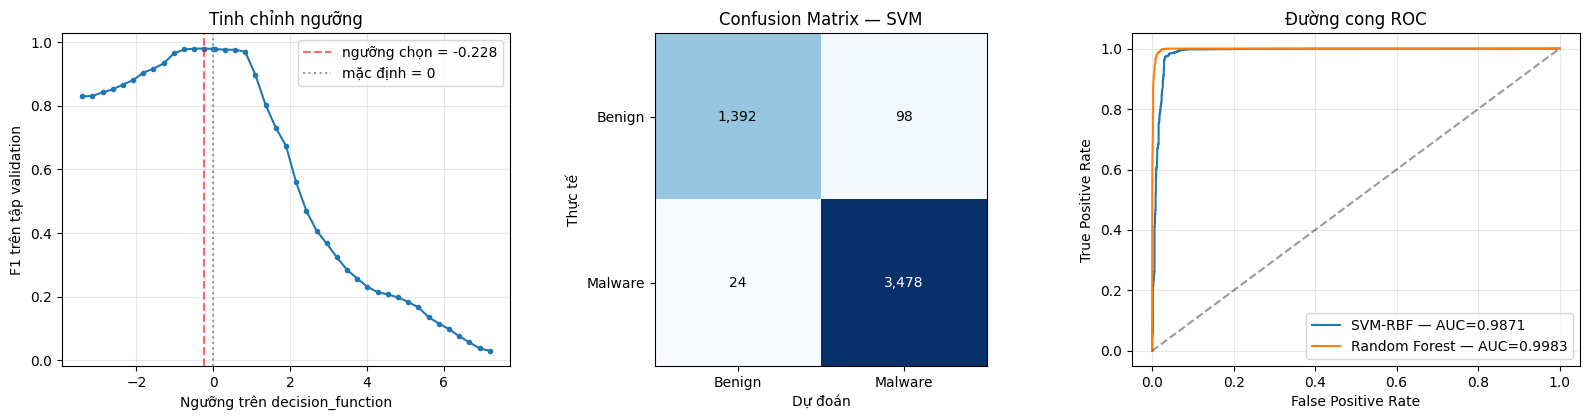

In [11]:
# Hai quyết định còn lại — có bật class_weight hay không, và chọn ngưỡng trên
# decision_function — phải đưa ra trên tập validation tách từ train, KHÔNG
# được dùng tập test.
#
# Với SVM, ngưỡng mặc định là 0 (nằm đúng trên siêu phẳng) chứ không phải 0,5
# như các mô hình xác suất.
X_a, X_v, y_a, y_v = train_test_split(X_tr, y_tr, test_size=0.2,
                                      random_state=SEED, stratify=y_tr)
print(f"Tách từ tập train: {X_a.shape[0]:,} mẫu để fit | "
      f"{X_v.shape[0]:,} mẫu validation")

pick = {}
for tag, w in [("None", None), ("balanced", "balanced")]:
    m = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=w).fit(X_a, y_a)
    pick[tag] = f1_score(y_v, m.predict(X_v), zero_division=0)
print("\nF1 trên tập validation:")
for k_, v in pick.items():
    print(f"   class_weight={k_:10s}: {v:.4f}")
CW = "balanced" if pick["balanced"] > pick["None"] else None
print(f"→ Chọn class_weight = {CW}")

m_val = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW).fit(X_a, y_a)
d_val = m_val.decision_function(X_v)
# Quét ngưỡng trong khoảng giá trị thực tế của decision_function trên
# validation, bỏ 1% hai đầu để tránh các giá trị ngoại lai.
lo, hi = np.percentile(d_val, 1), np.percentile(d_val, 99)
# Đưa cả giá trị 0 — ngưỡng mặc định của SVM — vào lưới. Nếu không, ngưỡng
# "tốt nhất" tìm được trên validation có thể còn kém hơn ngưỡng mặc định,
# chỉ vì 0 không nằm trong các điểm được quét.
THR_GRID = np.unique(np.concatenate([np.linspace(lo, hi, 41), [0.0]]))
f1_by_thr = [f1_score(y_v, (d_val >= t).astype(int), zero_division=0)
             for t in THR_GRID]
THR = float(THR_GRID[int(np.argmax(f1_by_thr))])
print(f"\n→ Ngưỡng tốt nhất trên validation: {THR:+.4f} "
      f"(F1 = {max(f1_by_thr):.4f}; tại ngưỡng mặc định 0 chỉ đạt "
      f"{f1_score(y_v, (d_val >= 0).astype(int), zero_division=0):.4f})")

# ── Mô hình cuối, huấn luyện lại trên toàn bộ tập train ────────────────────
final = SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW)
final.fit(X_tr, y_tr)
d_te = final.decision_function(X_te)
y_pred = (d_te >= THR).astype(int)

svm_res = evaluate(y_te, y_pred, d_te,
                   f"SVM-RBF (C={C_BEST:g}, ngưỡng {THR:+.3f})")
svm_res_0 = evaluate(y_te, (d_te >= 0).astype(int), d_te,
                     "SVM-RBF (ngưỡng mặc định 0)")

t0 = time.perf_counter()
SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW).fit(X_tr, y_tr)
t_svm = time.perf_counter() - t0

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr, y_tr)
t_rf = time.perf_counter() - t0
rf_score = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([svm_res_0, svm_res, rf_res]).set_index("model").round(4)
print()
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nSố support vector của mô hình cuối: {final.n_support_.sum():,} "
      f"({final.n_support_.sum()/len(y_tr)*100:.2f}% tập train)")
print(f"Thời gian huấn luyện: SVM {t_svm:.2f}s | Random Forest {t_rf:.2f}s")

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix SVM:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(THR_GRID, f1_by_thr, marker="o", ms=3)
axes[0].axvline(THR, color="red", ls="--", alpha=.6, label=f"ngưỡng chọn = {THR:+.3f}")
axes[0].axvline(0, color="gray", ls=":", alpha=.8, label="mặc định = 0")
axes[0].set_xlabel("Ngưỡng trên decision_function")
axes[0].set_ylabel("F1 trên tập validation")
axes[0].set_title("Tinh chỉnh ngưỡng")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — SVM")

for nm, sc in [("SVM-RBF", d_te), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend()
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A9. Kiểm Chứng Bằng 5-Fold Cross-Validation

Pipeline: StandardScaler → SVC(max_iter=MAX_ITER, kernel='rbf', C=100, gamma=scale, class_weight=None)


Chạy 5-fold mất 7.3 giây

F1 từng fold : [0.9822 0.9862 0.9834 0.9834 0.9851]
F1 trung bình: 0.9840 ± 0.0014
F1 của một lần chia train/test ở A8: 0.9828

Nhận xét: độ lệch chuẩn nhỏ (0,0014) → kết quả ổn định. Con số này chỉ đáng
tin vì đã lọc trùng ở A1; nếu còn dòng trùng lặp thì cross-validation cũng bị
thổi phồng y như một lần chia đơn lẻ.


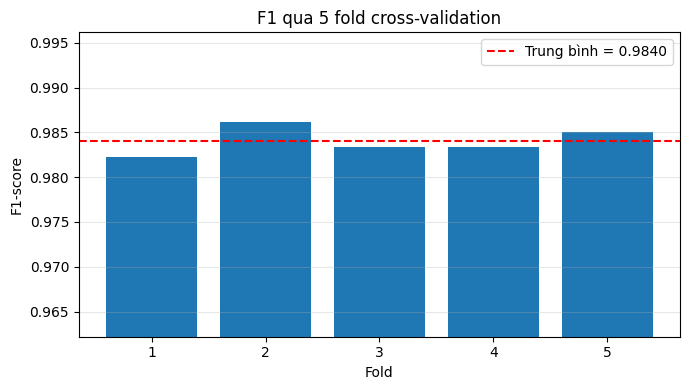

In [12]:
# StandardScaler phải nằm TRONG Pipeline để mỗi fold tự fit lại trên phần
# train của riêng nó. Với SVM điều này đặc biệt quan trọng: thuật toán dựa
# trên khoảng cách nên rất nhạy với thang đo đặc trưng.
pipe = Pipeline([
    ("sc", StandardScaler()),
    ("svm", SVC(max_iter=MAX_ITER, kernel="rbf", C=C_BEST, gamma=GAMMA_BEST, class_weight=CW)),
])
print("Pipeline: StandardScaler → SVC(max_iter=MAX_ITER, kernel='rbf', "
      f"C={C_BEST:g}, gamma={GAMMA_BEST}, class_weight={CW})")

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
t0 = time.perf_counter()
scores = cross_val_score(pipe, X_raw.values, y, cv=cv, scoring="f1", n_jobs=-1)
print(f"Chạy {CV_FOLDS}-fold mất {time.perf_counter() - t0:.1f} giây")

print(f"\nF1 từng fold : {np.round(scores, 4)}")
print(f"F1 trung bình: {scores.mean():.4f} ± {scores.std():.4f}")
print(f"F1 của một lần chia train/test ở A8: {svm_res['f1']:.4f}")
print(KFOLD_COMMENT)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(scores) + 1), scores)
ax.axhline(scores.mean(), color="red", ls="--",
           label=f"Trung bình = {scores.mean():.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_ylim(min(scores) - 0.02, max(scores) + 0.01)
ax.set_title(f"F1 qua {CV_FOLDS} fold cross-validation")
ax.legend()
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. RBF thắng (0,9748) nhưng chỉ nhích hơn kernel tuyến tính (0,9716); kernel đa thức bậc 3 tụt mạnh xuống 0,9101.
2. `LinearSVC` là mô hình chậm nhất ở phần A2 (3,61s) dù được thiết kế riêng cho trường hợp tuyến tính — dữ liệu PE không phân tách tuyến tính nên nó chạy hết số vòng lặp mà chưa hội tụ.
3. Cần `C` lớn (100) mới đạt hiệu năng tốt; ở `C=0,01` có tới 58% tập train là support vector.
4. Dò lưới có giá trị thật ở đây: 0,9748 → 0,9812. Ô kém nhất trong lưới chỉ 0,8246.
5. Brier score ≈0,02, cao gấp ba lần bộ dữ liệu của CV4.1 — hai lớp chồng lấn nhiều hơn.
6. Random Forest vượt rõ (F1 0,9937, AUC 0,9983) và còn huấn luyện nhanh hơn SVM, nên SVM không giữ được lợi thế nào.

**Câu hỏi thảo luận**

1. Vì sao kernel đa thức bậc 3 lại kém hơn cả kernel tuyến tính trên đặc trưng PE header? Hãy liên hệ với việc dữ liệu này có nhiều giá trị ngoại lai.
2. `LinearSVC` chậm hơn `SVC(kernel='linear')` hơn 10 lần ở phần A2. Giải thích nguyên nhân, và nêu khi nào thì `LinearSVC` mới thực sự có lợi thế.
3. Ở bộ dữ liệu của CV4.1 việc dò lưới gần như vô ích, còn ở đây nó cải thiện thật. Dựa trên số liệu của hai bài, hãy nêu một cách nhận biết sớm xem một bộ dữ liệu có "đáng dò lưới" hay không.
4. Đọc heatmap theo hàng: với `gamma` lớn thì tăng `C` không giúp gì. Giải thích hiện tượng này bằng ý nghĩa hình học của hai tham số.
5. Mô hình cuối báo giả 98 file lành tính. Với một sản phẩm diệt virus, hãy mô tả cụ thể cách dùng xác suất đã hiệu chỉnh ở phần A7 để kéo con số đó xuống, và cái giá phải trả.
6. Trên bộ dữ liệu này Random Forest tốt hơn SVM ở mọi tiêu chí, kể cả thời gian huấn luyện. Vậy giá trị của việc học SVM nằm ở đâu?
7. Phần A5 cho thấy chi phí huấn luyện tăng theo bình phương số mẫu. Nếu cơ sở dữ liệu mã độc có 50 triệu mẫu, hãy đề xuất một quy trình thực tế để vẫn dùng được SVM.
